In [1]:
# Text classification does not need torchvision; mismatched torchvision builds can break transformers imports.
%pip uninstall -y torchvision torchaudio torchtext
%pip install -q -U "transformers>=4.48,<5" accelerate scikit-learn pandas seaborn matplotlib nltk


Found existing installation: torchvision 0.26.0+cu128
Uninstalling torchvision-0.26.0+cu128:
  Successfully uninstalled torchvision-0.26.0+cu128
Found existing installation: torchaudio 2.11.0+cu128
Uninstalling torchaudio-2.11.0+cu128:
  Successfully uninstalled torchaudio-2.11.0+cu128
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 65.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 76.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 95.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 100.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 39.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 28.5 MB/s eta 0:00:00


In [2]:
# --- Shared setup: ELECTRA + RoBERTa hybrid experiments ---
import copy
import os
import random
import re
import time
from pathlib import Path

import nltk
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords, wordnet
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModel, AutoTokenizer

os.environ["WANDB_DISABLED"] = "true"
os.environ["TRANSFORMERS_NO_TF"] = "1"
os.environ["TRANSFORMERS_NO_FLAX"] = "1"

SPLIT_SEED = 42
TRAIN_SEEDS = [42, 123, 2024]
RANDOM_STATE = SPLIT_SEED
ELECTRA_MODEL_NAME = "google/electra-base-discriminator"
ROBERTA_MODEL_NAME = "roberta-base"
DATA_URL = "https://raw.githubusercontent.com/egbertbritannia-cpu/rbl-requirements-classification/main/data/exp/promise_exp.csv"
LOCAL_DATA_PATHS = [
    Path("data/exp/promise_exp.csv"),
    Path("../data/exp/promise_exp.csv"),
]

MAX_LENGTH = 128
NUM_EPOCHS = 30
LEARNING_RATE = 2e-5
TRAIN_BATCH_SIZE = 4
EVAL_BATCH_SIZE = 16
GRAD_ACCUM_STEPS = 4
EARLY_STOPPING_PATIENCE = 3
USE_GRADIENT_CHECKPOINTING = True

AUGMENTATION_TARGETS = {
    "FT": 200,
    "L": 200,
    "MN": 200,
    "A": 200,
    "LF": 200,
    "SC": 200,
    "PO": 200,
    "PE": 200,
    "O": 200,
    "US": 200,
    "SE": 100,
}
KEEP_WORDS = {"not", "no", "shall", "must", "should", "will", "cannot", "never", "only"}

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_all_seeds(SPLIT_SEED)

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
stop_words = set(stopwords.words("english")) - KEEP_WORDS


def normalize_requirement_text(text):
    return re.sub(r"\s+", " ", str(text)).strip()


def get_synonyms(word):
    clean_word = re.sub(r"[^a-zA-Z]", "", str(word).lower())
    if not clean_word:
        return []
    synonyms = set()
    for syn in wordnet.synsets(clean_word):
        for lemma in syn.lemmas():
            synonym = lemma.name().replace("_", " ").lower()
            if synonym != clean_word:
                synonyms.add(synonym)
    return list(synonyms)


def synonym_replacement(text, n=1):
    words = str(text).split()
    new_words = words.copy()
    candidates = list({
        word for word in words
        if re.sub(r"[^a-zA-Z]", "", word).lower() not in stop_words and len(word) > 3
    })
    random.shuffle(candidates)

    replaced = 0
    for word in candidates:
        synonyms = get_synonyms(word)
        if synonyms:
            synonym = random.choice(synonyms)
            new_words = [synonym if current == word else current for current in new_words]
            replaced += 1
        if replaced >= n:
            break
    return " ".join(new_words)


def phrase_insertion(text, n=1):
    phrases = ["the system shall", "must be able to", "should ensure that"]
    words = str(text).split()
    if not words:
        return str(text)
    for _ in range(n):
        words.insert(random.randint(0, len(words) - 1), random.choice(phrases))
    return " ".join(words)


def random_swap(text, n=1):
    words = str(text).split()
    if len(words) < 2:
        return str(text)
    for _ in range(n):
        i, j = random.sample(range(len(words)), 2)
        words[i], words[j] = words[j], words[i]
    return " ".join(words)


def random_deletion(text, p=0.1):
    words = str(text).split()
    if len(words) <= 1:
        return str(text)
    remaining = [word for word in words if random.random() > p]
    return " ".join(remaining) if remaining else random.choice(words)


def augment_requirement_text(text):
    text = synonym_replacement(text, n=1)
    text = phrase_insertion(text, n=1)
    text = random_swap(text, n=1)
    text = random_deletion(text, p=0.1)
    return normalize_requirement_text(text)


def load_promise_exp():
    for path in LOCAL_DATA_PATHS:
        if path.exists():
            print(f"Loaded PROMISE expanded dataset from local path: {path}")
            return pd.read_csv(path)
    print(f"Loaded PROMISE expanded dataset from URL: {DATA_URL}")
    return pd.read_csv(DATA_URL)


df = load_promise_exp()
df = df[["RequirementText", "class"]].dropna().reset_index(drop=True)
df["RequirementText"] = df["RequirementText"].astype(str).map(normalize_requirement_text)
df["class"] = df["class"].astype(str).str.strip().str.upper()
df = df[df["RequirementText"] != ""].reset_index(drop=True)
df = df[df["class"].map(df["class"].value_counts()) > 1].reset_index(drop=True)
df["model_text"] = df["RequirementText"]

label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["class"])
id2label = {idx: label for idx, label in enumerate(label_encoder.classes_)}
label2id = {label: idx for idx, label in id2label.items()}
num_labels = len(label_encoder.classes_)

train_df, val_test_df = train_test_split(
    df,
    test_size=0.3,
    stratify=df["label"],
    random_state=SPLIT_SEED,
)
val_df, test_df = train_test_split(
    val_test_df,
    test_size=0.5,
    stratify=val_test_df["label"],
    random_state=SPLIT_SEED,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Full distribution:", dict(df["class"].value_counts()))
print("Train distribution:", dict(train_df["class"].value_counts()))
print("Validation distribution:", dict(val_df["class"].value_counts()))
print("Test distribution:", dict(test_df["class"].value_counts()))
print("Labels:", list(label_encoder.classes_))
print("Using raw requirement text; no stopword/punctuation/digit removal.")


Loaded PROMISE expanded dataset from URL: https://raw.githubusercontent.com/egbertbritannia-cpu/rbl-requirements-classification/main/data/exp/promise_exp.csv
Full distribution: {'F': np.int64(444), 'SE': np.int64(125), 'US': np.int64(85), 'O': np.int64(77), 'PE': np.int64(67), 'LF': np.int64(49), 'A': np.int64(31), 'MN': np.int64(24), 'SC': np.int64(22), 'FT': np.int64(18), 'L': np.int64(15), 'PO': np.int64(12)}
Train distribution: {'F': np.int64(311), 'SE': np.int64(87), 'US': np.int64(59), 'O': np.int64(54), 'PE': np.int64(47), 'LF': np.int64(34), 'A': np.int64(22), 'MN': np.int64(17), 'SC': np.int64(15), 'FT': np.int64(13), 'L': np.int64(11), 'PO': np.int64(8)}
Validation distribution: {'F': np.int64(66), 'SE': np.int64(19), 'US': np.int64(13), 'O': np.int64(11), 'PE': np.int64(10), 'LF': np.int64(7), 'MN': np.int64(4), 'A': np.int64(4), 'SC': np.int64(4), 'FT': np.int64(3), 'PO': np.int64(2), 'L': np.int64(2)}
Test distribution: {'F': np.int64(67), 'SE': np.int64(19), 'US': np.int6

In [3]:
# --- Dataset, metrics, and PyTorch training loop ---
electra_tokenizer = AutoTokenizer.from_pretrained(ELECTRA_MODEL_NAME, use_fast=True)
roberta_tokenizer = AutoTokenizer.from_pretrained(ROBERTA_MODEL_NAME, use_fast=True)


class ElectraRobertaDataset(Dataset):
    def __init__(self, frame):
        texts = frame["model_text"].astype(str).tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.electra = electra_tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
            return_token_type_ids=True,
        )
        self.roberta = roberta_tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            "electra_input_ids": torch.tensor(self.electra["input_ids"][idx], dtype=torch.long),
            "electra_attention_mask": torch.tensor(self.electra["attention_mask"][idx], dtype=torch.long),
            "roberta_input_ids": torch.tensor(self.roberta["input_ids"][idx], dtype=torch.long),
            "roberta_attention_mask": torch.tensor(self.roberta["attention_mask"][idx], dtype=torch.long),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long),
        }
        if "token_type_ids" in self.electra:
            item["electra_token_type_ids"] = torch.tensor(self.electra["token_type_ids"][idx], dtype=torch.long)
        return item


def make_loaders(train_frame, seed=None):
    train_ds = ElectraRobertaDataset(train_frame)
    val_ds = ElectraRobertaDataset(val_df)
    test_ds = ElectraRobertaDataset(test_df)
    generator = None
    if seed is not None:
        generator = torch.Generator()
        generator.manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=TRAIN_BATCH_SIZE, shuffle=True, generator=generator)
    val_loader = DataLoader(val_ds, batch_size=EVAL_BATCH_SIZE)
    test_loader = DataLoader(test_ds, batch_size=EVAL_BATCH_SIZE)
    return train_loader, val_loader, test_loader


def compute_class_weights(frame):
    counts = frame["label"].value_counts().sort_index()
    weights = len(frame) / (len(counts) * counts)
    return torch.tensor(weights.values, dtype=torch.float)


def compute_metrics_from_arrays(labels, preds):
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        labels, preds, average="weighted", zero_division=0
    )
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": weighted_p,
        "recall": weighted_r,
        "f1": weighted_f1,
        "precision_macro": macro_p,
        "recall_macro": macro_r,
        "macro_F1": macro_f1,
    }


@torch.no_grad()
def evaluate_model(model, data_loader, device):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    for batch in data_loader:
        batch = {key: value.to(device) for key, value in batch.items()}
        outputs = model(**batch)
        total_loss += outputs["loss"].item()
        preds = outputs["logits"].argmax(dim=-1)
        all_labels.extend(batch["labels"].detach().cpu().numpy())
        all_preds.extend(preds.detach().cpu().numpy())

    labels = np.array(all_labels)
    preds = np.array(all_preds)
    metrics = compute_metrics_from_arrays(labels, preds)
    metrics["loss"] = total_loss / max(1, len(data_loader))
    return metrics, labels, preds


def train_model(model, train_loader, val_loader, run_name):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

    best_state = None
    best_macro_F1 = -1.0
    patience_left = EARLY_STOPPING_PATIENCE

    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        total_loss = 0.0
        optimizer.zero_grad(set_to_none=True)

        for step, batch in enumerate(train_loader, start=1):
            batch = {key: value.to(device) for key, value in batch.items()}
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                outputs = model(**batch)
                loss = outputs["loss"] / GRAD_ACCUM_STEPS

            scaler.scale(loss).backward()
            total_loss += loss.item() * GRAD_ACCUM_STEPS

            if step % GRAD_ACCUM_STEPS == 0 or step == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)

        val_metrics, _, _ = evaluate_model(model, val_loader, device)
        train_loss = total_loss / max(1, len(train_loader))
        print(
            f"{run_name} | Epoch {epoch:02d} | train_loss={train_loss:.4f} "
            f"| val_loss={val_metrics['loss']:.4f} | val_macro_F1={val_metrics['macro_F1']:.4f}"
        )

        if val_metrics["macro_F1"] > best_macro_F1:
            best_macro_F1 = val_metrics["macro_F1"]
            best_state = copy.deepcopy(model.state_dict())
            patience_left = EARLY_STOPPING_PATIENCE
        else:
            patience_left -= 1
            if patience_left == 0:
                print(f"{run_name} early stopping triggered.")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, device


def evaluate_and_plot(model, device, test_loader, run_name):
    metrics, labels, preds = evaluate_model(model, test_loader, device)
    print(f"{run_name} test metrics:", metrics)
    print(classification_report(
        labels,
        preds,
        target_names=label_encoder.classes_,
        zero_division=0,
    ))

    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        cmap="Blues",
    )
    plt.title(f"Confusion Matrix - {run_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    return metrics


def summarize_seed_results(results_df, metric_columns):
    summary = results_df[metric_columns].agg(["mean", "std"]).T
    summary["mean ± std"] = summary.apply(
        lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}",
        axis=1,
    )
    return summary


def run_fusion_experiments(train_frame, experiment_name, run_seed=None, run_gated=True):
    if run_seed is None:
        run_seed = RANDOM_STATE
    set_all_seeds(run_seed)
    train_loader, val_loader, test_loader = make_loaders(train_frame, seed=run_seed)
    class_weights = compute_class_weights(train_frame)
    results = []

    start_time = time.perf_counter()
    naive_model = ElectraRobertaNaiveFusion(num_labels=num_labels, class_weights=class_weights)
    naive_model = enable_memory_saving(naive_model)
    naive_model, naive_device = train_model(
        naive_model,
        train_loader,
        val_loader,
        run_name=f"ELECTRA+RoBERTa Naive Fusion ({experiment_name}, seed={run_seed})",
    )
    naive_metrics = evaluate_and_plot(
        naive_model,
        naive_device,
        test_loader,
        run_name=f"ELECTRA+RoBERTa Naive Fusion ({experiment_name}, seed={run_seed})",
    )
    naive_metrics["runtime_seconds"] = time.perf_counter() - start_time
    naive_metrics["seed"] = run_seed
    results.append({"model": f"ELECTRA+RoBERTa Naive Fusion ({experiment_name})", **naive_metrics})
    print(f"ELECTRA+RoBERTa Naive Fusion ({experiment_name}) | seed={run_seed} | runtime_seconds={naive_metrics['runtime_seconds']:.2f}")

    if run_gated:
        start_time = time.perf_counter()
        gated_model = ElectraRobertaGatedFusion(num_labels=num_labels, class_weights=class_weights)
        gated_model = enable_memory_saving(gated_model)
        gated_model, gated_device = train_model(
            gated_model,
            train_loader,
            val_loader,
            run_name=f"ELECTRA+RoBERTa Gated Fusion ({experiment_name}, seed={run_seed})",
        )
        gated_metrics = evaluate_and_plot(
            gated_model,
            gated_device,
            test_loader,
            run_name=f"ELECTRA+RoBERTa Gated Fusion ({experiment_name}, seed={run_seed})",
        )
        gated_metrics["runtime_seconds"] = time.perf_counter() - start_time
        gated_metrics["seed"] = run_seed
        results.append({"model": f"ELECTRA+RoBERTa Gated Fusion ({experiment_name})", **gated_metrics})
        print(f"ELECTRA+RoBERTa Gated Fusion ({experiment_name}) | seed={run_seed} | runtime_seconds={gated_metrics['runtime_seconds']:.2f}")

    return results


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [4]:
# --- ELECTRA + RoBERTa fusion models ---
def cls_pool(outputs):
    return outputs.last_hidden_state[:, 0, :]


def enable_memory_saving(model):
    if USE_GRADIENT_CHECKPOINTING:
        for encoder in [model.electra_encoder, model.roberta_encoder]:
            if hasattr(encoder, "gradient_checkpointing_enable"):
                encoder.gradient_checkpointing_enable()
    return model


def freeze_lower_encoder_layers(encoder):
    # Freeze lower transformer layers to reduce overfitting on short requirement texts.
    for layer in encoder.encoder.layer[:8]:
        for param in layer.parameters():
            param.requires_grad = False


def report_trainable_and_frozen_parameters(model, model_name):
    trainable_params = sum(param.numel() for param in model.parameters() if param.requires_grad)
    frozen_params = sum(param.numel() for param in model.parameters() if not param.requires_grad)
    print(f"{model_name} trainable parameters: {trainable_params:,}")
    print(f"{model_name} frozen parameters: {frozen_params:,}")


class ElectraRobertaNaiveFusion(nn.Module):
    def __init__(self, num_labels, class_weights=None):
        super().__init__()
        self.electra_encoder = AutoModel.from_pretrained(ELECTRA_MODEL_NAME)
        self.roberta_encoder = AutoModel.from_pretrained(ROBERTA_MODEL_NAME)
        freeze_lower_encoder_layers(self.electra_encoder)
        freeze_lower_encoder_layers(self.roberta_encoder)
        electra_hidden = self.electra_encoder.config.hidden_size
        roberta_hidden = self.roberta_encoder.config.hidden_size
        fusion_size = electra_hidden + roberta_hidden
        self.dropout = nn.Dropout(0.2)
        self.fusion = nn.Sequential(
            nn.LayerNorm(fusion_size),
            nn.Linear(fusion_size, 768),
            nn.GELU(),
            nn.Dropout(0.2),
        )
        self.classifier = nn.Linear(768, num_labels)
        self.register_buffer("class_weights", class_weights if class_weights is not None else torch.ones(num_labels))
        report_trainable_and_frozen_parameters(self, "ElectraRobertaNaiveFusion")

    def forward(
        self,
        electra_input_ids,
        electra_attention_mask,
        roberta_input_ids,
        roberta_attention_mask,
        labels=None,
        electra_token_type_ids=None,
    ):
        electra_kwargs = {"input_ids": electra_input_ids, "attention_mask": electra_attention_mask}
        if electra_token_type_ids is not None:
            electra_kwargs["token_type_ids"] = electra_token_type_ids

        h_electra = cls_pool(self.electra_encoder(**electra_kwargs))
        h_roberta = cls_pool(self.roberta_encoder(
            input_ids=roberta_input_ids,
            attention_mask=roberta_attention_mask,
        ))
        h = torch.cat([h_electra, h_roberta], dim=-1)
        logits = self.classifier(self.fusion(self.dropout(h)))

        loss = None
        if labels is not None:
            loss = nn.functional.cross_entropy(logits, labels, weight=self.class_weights)
        return {"loss": loss, "logits": logits}


class ElectraRobertaGatedFusion(nn.Module):
    def __init__(self, num_labels, class_weights=None):
        super().__init__()
        self.electra_encoder = AutoModel.from_pretrained(ELECTRA_MODEL_NAME)
        self.roberta_encoder = AutoModel.from_pretrained(ROBERTA_MODEL_NAME)
        freeze_lower_encoder_layers(self.electra_encoder)
        freeze_lower_encoder_layers(self.roberta_encoder)
        electra_hidden = self.electra_encoder.config.hidden_size
        roberta_hidden = self.roberta_encoder.config.hidden_size
        shared_hidden = 768
        self.electra_projection = nn.Linear(electra_hidden, shared_hidden)
        self.roberta_projection = nn.Linear(roberta_hidden, shared_hidden)
        self.gate = nn.Sequential(
            nn.LayerNorm(shared_hidden * 2),
            nn.Linear(shared_hidden * 2, shared_hidden),
            nn.Sigmoid(),
        )
        self.dropout = nn.Dropout(0.2)
        self.classifier = nn.Sequential(
            nn.LayerNorm(shared_hidden),
            nn.Linear(shared_hidden, shared_hidden),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(shared_hidden, num_labels),
        )
        self.register_buffer("class_weights", class_weights if class_weights is not None else torch.ones(num_labels))
        report_trainable_and_frozen_parameters(self, "ElectraRobertaGatedFusion")

    def forward(
        self,
        electra_input_ids,
        electra_attention_mask,
        roberta_input_ids,
        roberta_attention_mask,
        labels=None,
        electra_token_type_ids=None,
    ):
        electra_kwargs = {"input_ids": electra_input_ids, "attention_mask": electra_attention_mask}
        if electra_token_type_ids is not None:
            electra_kwargs["token_type_ids"] = electra_token_type_ids

        h_electra = cls_pool(self.electra_encoder(**electra_kwargs))
        h_roberta = cls_pool(self.roberta_encoder(
            input_ids=roberta_input_ids,
            attention_mask=roberta_attention_mask,
        ))
        h_electra = self.electra_projection(h_electra)
        h_roberta = self.roberta_projection(h_roberta)
        h_concat = torch.cat([h_electra, h_roberta], dim=-1)
        gate = self.gate(h_concat)
        h_fused = gate * h_electra + (1.0 - gate) * h_roberta
        logits = self.classifier(self.dropout(h_fused))

        loss = None
        if labels is not None:
            loss = nn.functional.cross_entropy(logits, labels, weight=self.class_weights)
        return {"loss": loss, "logits": logits}


pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ElectraRobertaNaiveFusion trainable parameters: 121,324,044
ElectraRobertaNaiveFusion frozen parameters: 113,405,952


...

ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=42) | Epoch 06 | train_loss=0.5119 | val_loss=1.1439 | val_macro_F1=0.6818


/tmp/ipykernel_955/1313723662.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=42) | Epoch 07 | train_loss=0.3176 | val_loss=1.1179 | val_macro_F1=0.6808


/tmp/ipykernel_955/1313723662.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=42) | Epoch 08 | train_loss=0.2017 | val_loss=1.2021 | val_macro_F1=0.6325
ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=42) early stopping triggered.
ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=42) test metrics: {'accuracy': 0.8767123287671232, 'precision': 0.8876767269797085, 'recall': 0.8767123287671232, 'f1': 0.8766188133060836, 'precision_macro': 0.8475972964943552, 'recall_macro': 0.7799017312224303, 'macro_F1': 0.7953406451272306, 'loss': 0.8316683694720268}
              precision    recall  f1-score   support

           A       1.00      0.60      0.75         5
           F       0.93      0.94      0.93        67
          FT       1.00      1.00      1.00         2
           L       0.67      1.00      0.80         2
          LF       0.88      0.88      0.88         8
          MN       0.25      0.33      0.29         3
           O       0.90      0.75      0.82        12
          PE    

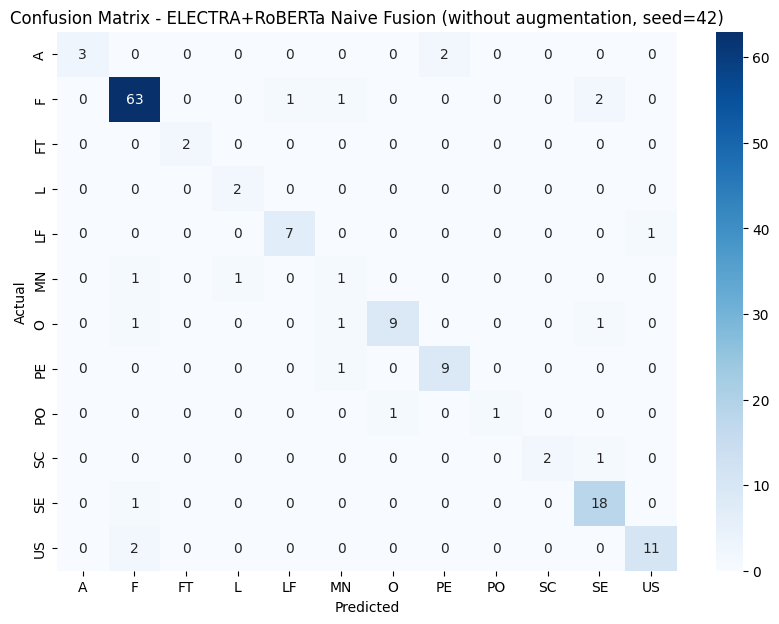

ELECTRA+RoBERTa Naive Fusion (without augmentation) | seed=42 | runtime_seconds=233.55


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ElectraRobertaNaiveFusion trainable parameters: 121,324,044
ElectraRobertaNaiveFusion frozen parameters: 113,405,952


/tmp/ipykernel_955/1313723662.py:104: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_955/1313723662.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=123) | Epoch 01 | train_loss=2.4296 | val_loss=2.4823 | val_macro_F1=0.0819


...

ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=123) | Epoch 07 | train_loss=0.3680 | val_loss=1.0641 | val_macro_F1=0.5862


/tmp/ipykernel_955/1313723662.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=123) | Epoch 08 | train_loss=0.2437 | val_loss=1.2263 | val_macro_F1=0.6365


/tmp/ipykernel_955/1313723662.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=123) | Epoch 09 | train_loss=0.1579 | val_loss=1.3564 | val_macro_F1=0.6261
ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=123) early stopping triggered.
ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=123) test metrics: {'accuracy': 0.863013698630137, 'precision': 0.8974006476925855, 'recall': 0.863013698630137, 'f1': 0.8650345183735595, 'precision_macro': 0.8078650806792883, 'recall_macro': 0.8165072075519837, 'macro_F1': 0.7815986599953991, 'loss': 0.7381579354405403}
              precision    recall  f1-score   support

           A       1.00      0.40      0.57         5
           F       0.98      0.90      0.94        67
          FT       0.67      1.00      0.80         2
           L       1.00      1.00      1.00         2
          LF       0.80      1.00      0.89         8
          MN       0.50      1.00      0.67         3
           O       0.89      0.67      0.76        12
          PE   

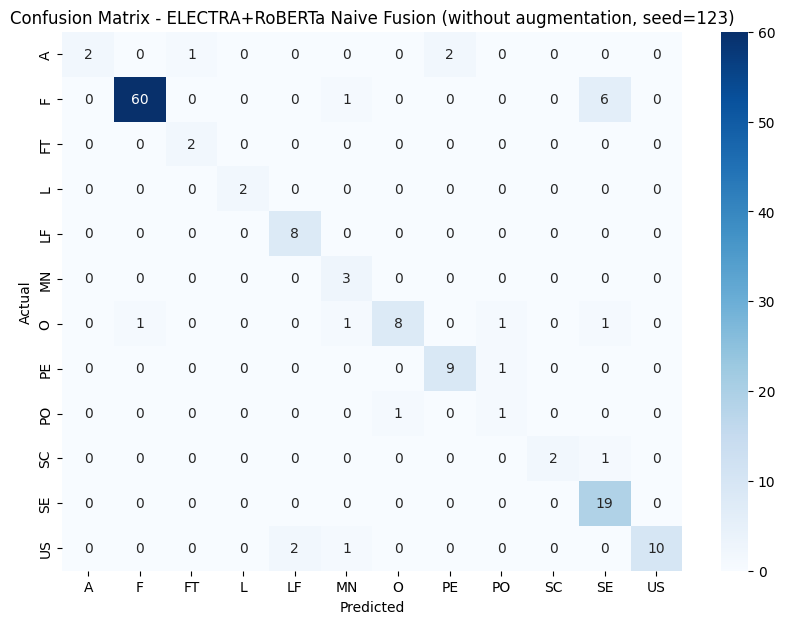

ELECTRA+RoBERTa Naive Fusion (without augmentation) | seed=123 | runtime_seconds=207.40


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ElectraRobertaNaiveFusion trainable parameters: 121,324,044
ElectraRobertaNaiveFusion frozen parameters: 113,405,952


/tmp/ipykernel_955/1313723662.py:104: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_955/1313723662.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=2024) | Epoch 01 | train_loss=2.4056 | val_loss=2.4407 | val_macro_F1=0.0524


...

ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=2024) | Epoch 05 | train_loss=0.8350 | val_loss=1.0212 | val_macro_F1=0.6699


/tmp/ipykernel_955/1313723662.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=2024) | Epoch 06 | train_loss=0.5539 | val_loss=1.0070 | val_macro_F1=0.6095


/tmp/ipykernel_955/1313723662.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=2024) | Epoch 07 | train_loss=0.3652 | val_loss=0.9900 | val_macro_F1=0.6536
ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=2024) early stopping triggered.
ELECTRA+RoBERTa Naive Fusion (without augmentation, seed=2024) test metrics: {'accuracy': 0.8424657534246576, 'precision': 0.8589583932049685, 'recall': 0.8424657534246576, 'f1': 0.8328275012775689, 'precision_macro': 0.7845522533022532, 'recall_macro': 0.6767882920082449, 'macro_F1': 0.6892848807162029, 'loss': 1.1140759199857713}
              precision    recall  f1-score   support

           A       1.00      0.40      0.57         5
           F       0.94      0.93      0.93        67
          FT       1.00      0.50      0.67         2
           L       1.00      1.00      1.00         2
          LF       0.62      1.00      0.76         8
          MN       1.00      0.33      0.50         3
           O       0.62      0.83      0.71        12
          

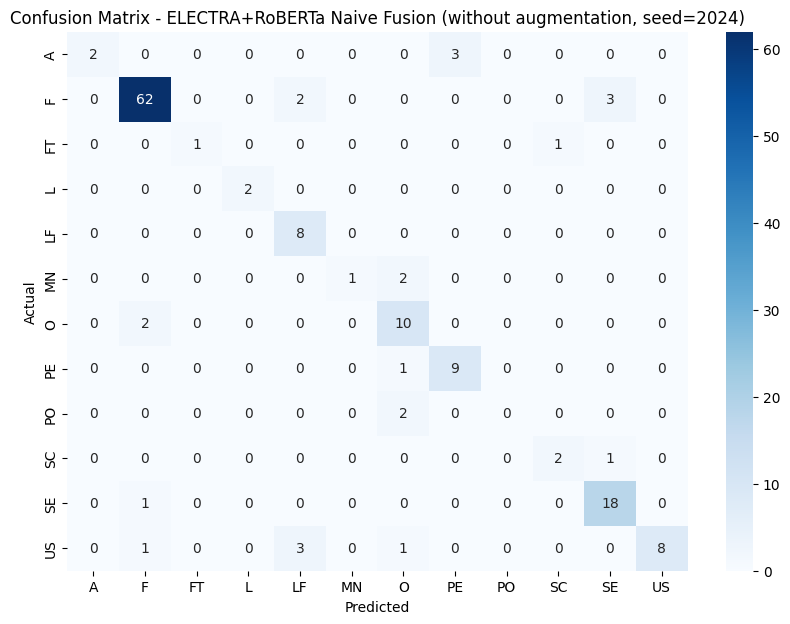

ELECTRA+RoBERTa Naive Fusion (without augmentation) | seed=2024 | runtime_seconds=161.19
ELECTRA+RoBERTa Naive Fusion without augmentation seed-level results:
                                               model  accuracy  precision  \
0  ELECTRA+RoBERTa Naive Fusion (without augmenta...  0.876712   0.887677   
1  ELECTRA+RoBERTa Naive Fusion (without augmenta...  0.863014   0.897401   
2  ELECTRA+RoBERTa Naive Fusion (without augmenta...  0.842466   0.858958   

     recall        f1  precision_macro  recall_macro  macro_F1      loss  \
0  0.876712  0.876619         0.847597      0.779902  0.795341  0.831668   
1  0.863014  0.865035         0.807865      0.816507  0.781599  0.738158   
2  0.842466  0.832828         0.784552      0.676788  0.689285  1.114076   

   runtime_seconds  seed  
0       233.546988    42  
1       207.402604   123  
2       161.187741  2024  
ELECTRA+RoBERTa Naive Fusion without augmentation mean ± std:
                       mean        std          mean ± st

In [5]:
# --- ELECTRA + RoBERTa Naive Fusion WITHOUT Augmentation: 3 fixed training seeds ---
# Split is fixed by SPLIT_SEED=42 in the shared setup. Only training/model seeds vary here.
no_aug_results = []
for run_seed in TRAIN_SEEDS:
    no_aug_results.extend(
        run_fusion_experiments(
            train_df,
            "without augmentation",
            run_seed=run_seed,
            run_gated=False,
        )
    )

no_aug_results_df = pd.DataFrame(no_aug_results)
metric_columns = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "precision_macro",
    "recall_macro",
    "macro_F1",
    "loss",
    "runtime_seconds",
]
no_aug_summary = summarize_seed_results(no_aug_results_df, metric_columns)

print("ELECTRA+RoBERTa Naive Fusion without augmentation seed-level results:")
print(no_aug_results_df)
print("ELECTRA+RoBERTa Naive Fusion without augmentation mean ± std:")
print(no_aug_summary)


Augmented rows added: 1733
Augmented train distribution: {'F': np.int64(311), 'PE': np.int64(200), 'US': np.int64(200), 'FT': np.int64(200), 'O': np.int64(200), 'SC': np.int64(200), 'LF': np.int64(200), 'A': np.int64(200), 'PO': np.int64(200), 'MN': np.int64(200), 'L': np.int64(200), 'SE': np.int64(100)}


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ElectraRobertaNaiveFusion trainable parameters: 121,324,044
ElectraRobertaNaiveFusion frozen parameters: 113,405,952


/tmp/ipykernel_955/1313723662.py:104: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_955/1313723662.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion (with augmentation, seed=42) | Epoch 01 | train_loss=2.0057 | val_loss=0.9852 | val_macro_F1=0.5426


...

ELECTRA+RoBERTa Naive Fusion (with augmentation, seed=42) | Epoch 08 | train_loss=0.0048 | val_loss=1.0315 | val_macro_F1=0.6130


/tmp/ipykernel_955/1313723662.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion (with augmentation, seed=42) | Epoch 09 | train_loss=0.0040 | val_loss=0.9002 | val_macro_F1=0.6577


/tmp/ipykernel_955/1313723662.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion (with augmentation, seed=42) | Epoch 10 | train_loss=0.0049 | val_loss=0.8343 | val_macro_F1=0.6416
ELECTRA+RoBERTa Naive Fusion (with augmentation, seed=42) early stopping triggered.
ELECTRA+RoBERTa Naive Fusion (with augmentation, seed=42) test metrics: {'accuracy': 0.863013698630137, 'precision': 0.8571595256526764, 'recall': 0.863013698630137, 'f1': 0.853872975937845, 'precision_macro': 0.7726931476931477, 'recall_macro': 0.7189755507214266, 'macro_F1': 0.7286035320933563, 'loss': 0.6052714935038239}
              precision    recall  f1-score   support

           A       1.00      0.60      0.75         5
           F       0.88      0.97      0.92        67
          FT       0.50      1.00      0.67         2
           L       1.00      1.00      1.00         2
          LF       1.00      0.75      0.86         8
          MN       0.50      0.33      0.40         3
           O       0.73      0.67      0.70        12
          PE       0.90     

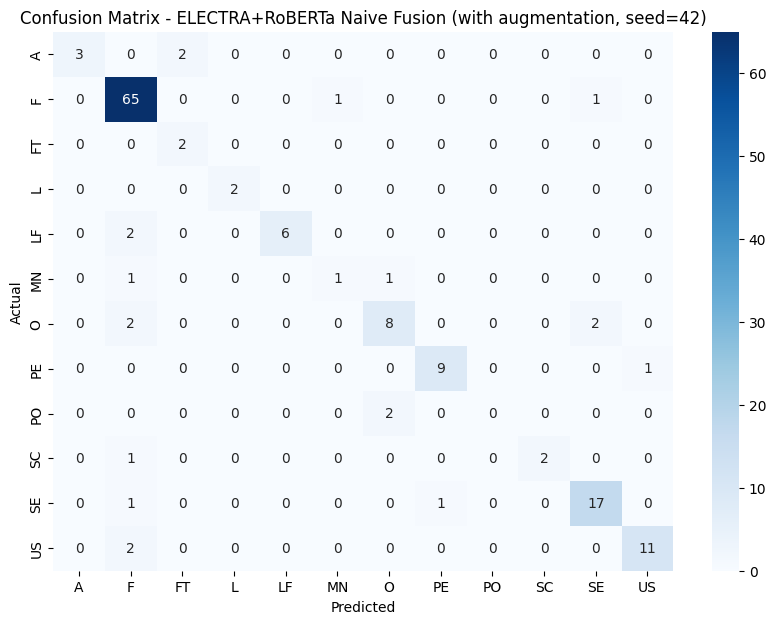

ELECTRA+RoBERTa Naive Fusion (with augmentation) | seed=42 | runtime_seconds=754.78


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ElectraRobertaGatedFusion trainable parameters: 123,097,356
ElectraRobertaGatedFusion frozen parameters: 113,405,952


/tmp/ipykernel_955/1313723662.py:104: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_955/1313723662.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Gated Fusion (with augmentation, seed=42) | Epoch 01 | train_loss=1.9444 | val_loss=0.9733 | val_macro_F1=0.5930


...

ELECTRA+RoBERTa Gated Fusion (with augmentation, seed=42) | Epoch 04 | train_loss=0.1061 | val_loss=0.8210 | val_macro_F1=0.6342


/tmp/ipykernel_955/1313723662.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Gated Fusion (with augmentation, seed=42) | Epoch 05 | train_loss=0.0471 | val_loss=0.7983 | val_macro_F1=0.6256


/tmp/ipykernel_955/1313723662.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Gated Fusion (with augmentation, seed=42) | Epoch 06 | train_loss=0.0147 | val_loss=0.9790 | val_macro_F1=0.6418
ELECTRA+RoBERTa Gated Fusion (with augmentation, seed=42) early stopping triggered.
ELECTRA+RoBERTa Gated Fusion (with augmentation, seed=42) test metrics: {'accuracy': 0.8561643835616438, 'precision': 0.8368603175977917, 'recall': 0.8561643835616438, 'f1': 0.8410163366045718, 'precision_macro': 0.7038285914998244, 'recall_macro': 0.6994147430861886, 'macro_F1': 0.6920692869222281, 'loss': 0.47756144050508736}
              precision    recall  f1-score   support

           A       1.00      0.60      0.75         5
           F       0.88      0.96      0.91        67
          FT       0.67      1.00      0.80         2
           L       1.00      1.00      1.00         2
          LF       0.78      0.88      0.82         8
          MN       0.00      0.00      0.00         3
           O       0.77      0.83      0.80        12
          PE       0.90 

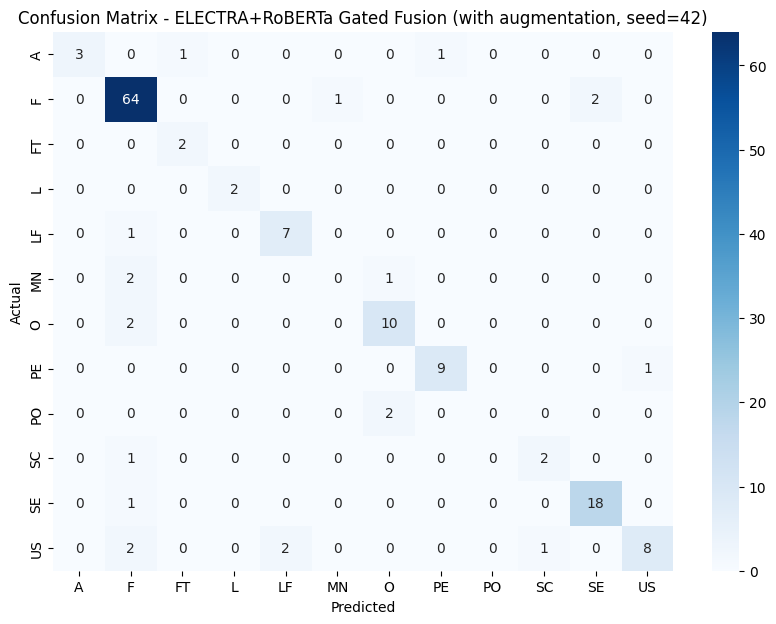

ELECTRA+RoBERTa Gated Fusion (with augmentation) | seed=42 | runtime_seconds=467.81


In [6]:
# --- ELECTRA + RoBERTa WITH Augmentation ---
augmented_rows = []
train_counts = train_df["class"].value_counts().to_dict()

for cls, target_count in AUGMENTATION_TARGETS.items():
    current_count = train_counts.get(cls, 0)
    needed = max(0, target_count - current_count)
    if needed == 0:
        continue
    class_df = train_df[train_df["class"] == cls].reset_index(drop=True)
    if class_df.empty:
        continue
    for _ in range(needed):
        row = class_df.sample(n=1, random_state=random.randint(0, 10**9)).iloc[0]
        aug_text = augment_requirement_text(row["RequirementText"])
        augmented_rows.append({
            "RequirementText": aug_text,
            "class": cls,
            "model_text": aug_text,
            "label": int(row["label"]),
        })

df_aug = pd.DataFrame(augmented_rows)
train_aug_df = pd.concat([train_df, df_aug], ignore_index=True) if len(df_aug) > 0 else train_df.copy()
train_aug_df = train_aug_df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("Augmented rows added:", len(df_aug))
print("Augmented train distribution:", dict(train_aug_df["class"].value_counts()))

aug_results = run_fusion_experiments(train_aug_df, "with augmentation")


In [7]:
# --- Comparison summary ---
comparison_df = pd.DataFrame(no_aug_results + aug_results)
display(comparison_df)


,model,accuracy,precision,recall,f1,precision_macro,recall_macro,macro_F1,loss,runtime_seconds,seed
0,ELECTRA+RoBERTa Naive Fusion (without augmenta...,0.876712,0.887677,0.876712,0.876619,0.847597,0.779902,0.795341,0.831668,233.546988,42
1,ELECTRA+RoBERTa Naive Fusion (without augmenta...,0.863014,0.897401,0.863014,0.865035,0.807865,0.816507,0.781599,0.738158,207.402604,123
2,ELECTRA+RoBERTa Naive Fusion (without augmenta...,0.842466,0.858958,0.842466,0.832828,0.784552,0.676788,0.689285,1.114076,161.187741,2024
3,ELECTRA+RoBERTa Naive Fusion (with augmentation),0.863014,0.857160,0.863014,0.853873,0.772693,0.718976,0.728604,0.605271,754.776404,42
4,ELECTRA+RoBERTa Gated Fusion (with augmentation),0.856164,0.836860,0.856164,0.841016,0.703829,0.699415,0.692069,0.477561,467.812552,42
